# Exploración del corpus dental

Cristhian Pazmino Parra · Universidad Espíritu Santo

Recalcula denominadores sobre la cohorte inmutable y muestra gráficos agregados del EDA ejecutado.

Referente: anotaciones publicadas sin adjudicación local. Los datos permanecen fuera del repositorio.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd()
assert (ROOT / "src").is_dir(), "Ejecutar desde la raíz del repositorio"
sys.path.insert(0, str(ROOT))
LOCAL = Path.home() / "AppData/Local/DentalAI"
DATA = LOCAL / "data/research_v2"
REPORTS = ROOT / "reports/completion"
def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))
from IPython.display import display, Markdown, Image


In [2]:
cohort = read(DATA / "cohort_report.json")
assert cohort["raw_images"] == cohort["accepted_images"] + cohort["excluded_images"]
display(cohort)

{'raw_images': 1808,
 'accepted_images': 1066,
 'excluded_images': 742,
 'exclusion_reasons': {'annotation_disagreement_between_exact_copies': 372,
  'unconfirmed_class_remap': 98,
  'unconfirmed_visual_reexport': 37,
  'no_target_objects_and_unverified_negative_coverage': 68,
  'redundant_exact_copy': 6,
  'historically_ambiguous_annotation_block': 158,
  'invalid_annotation': 3},
 'partitions': {'train': {'images': 681,
   'boxes': {'caries': 1426,
    'lesion_periapical': 471,
    'diente_impactado': 371,
    'restauracion': 2298,
    'endodoncia': 1617,
    'protesis_fija': 760,
    'implante': 185}},
  'val': {'images': 121,
   'boxes': {'caries': 263,
    'lesion_periapical': 88,
    'diente_impactado': 69,
    'restauracion': 385,
    'endodoncia': 277,
    'protesis_fija': 138,
    'implante': 34}},
  'test': {'images': 94,
   'boxes': {'caries': 137,
    'lesion_periapical': 80,
    'diente_impactado': 56,
    'restauracion': 385,
    'endodoncia': 261,
    'protesis_fija': 89

In [3]:
from collections import Counter
manifest = [json.loads(s) for s in (DATA / "manifest.jsonl").read_text().splitlines()]
counts = Counter(r["split"] for r in manifest)
assert counts == {k:v["images"] for k,v in cohort["partitions"].items()}
display(dict(counts))

{'test': 94, 'external': 170, 'train': 681, 'val': 121}

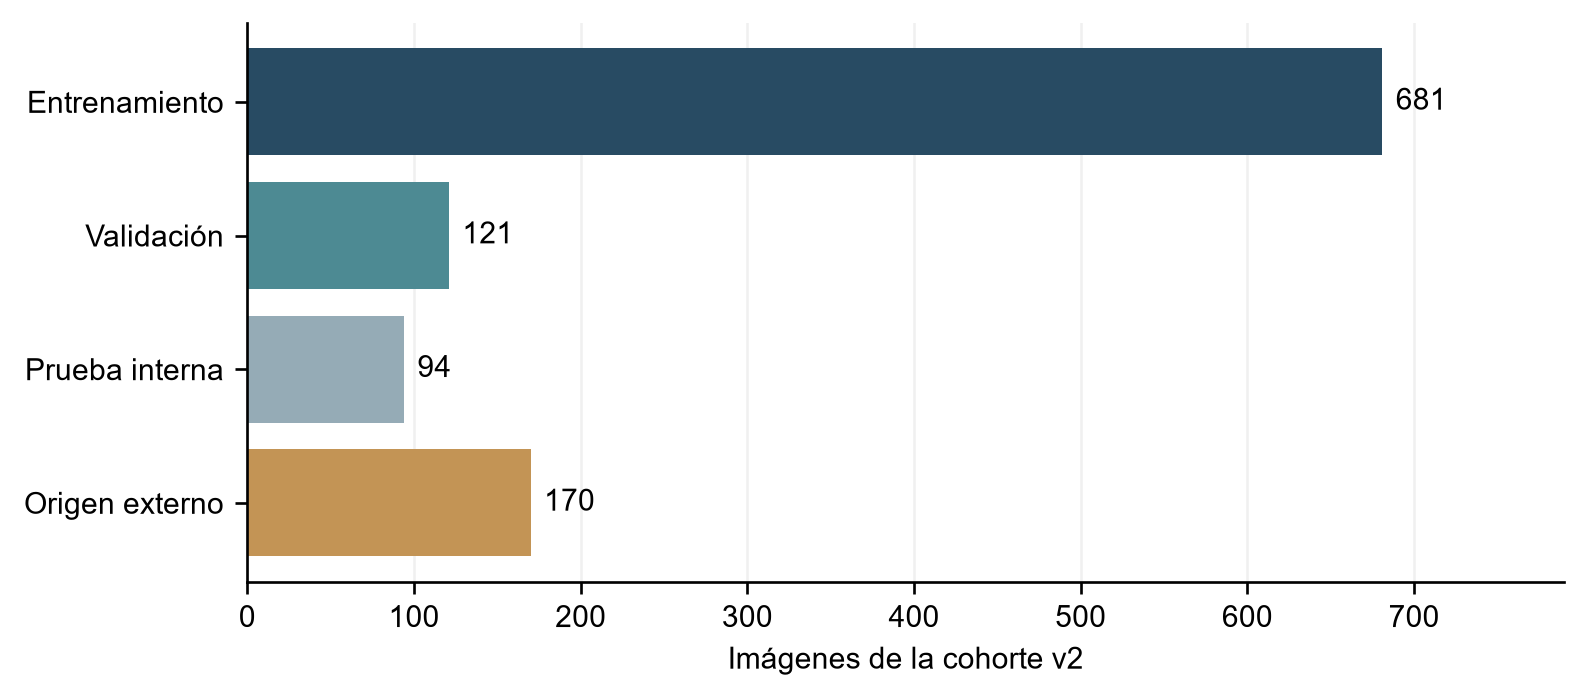

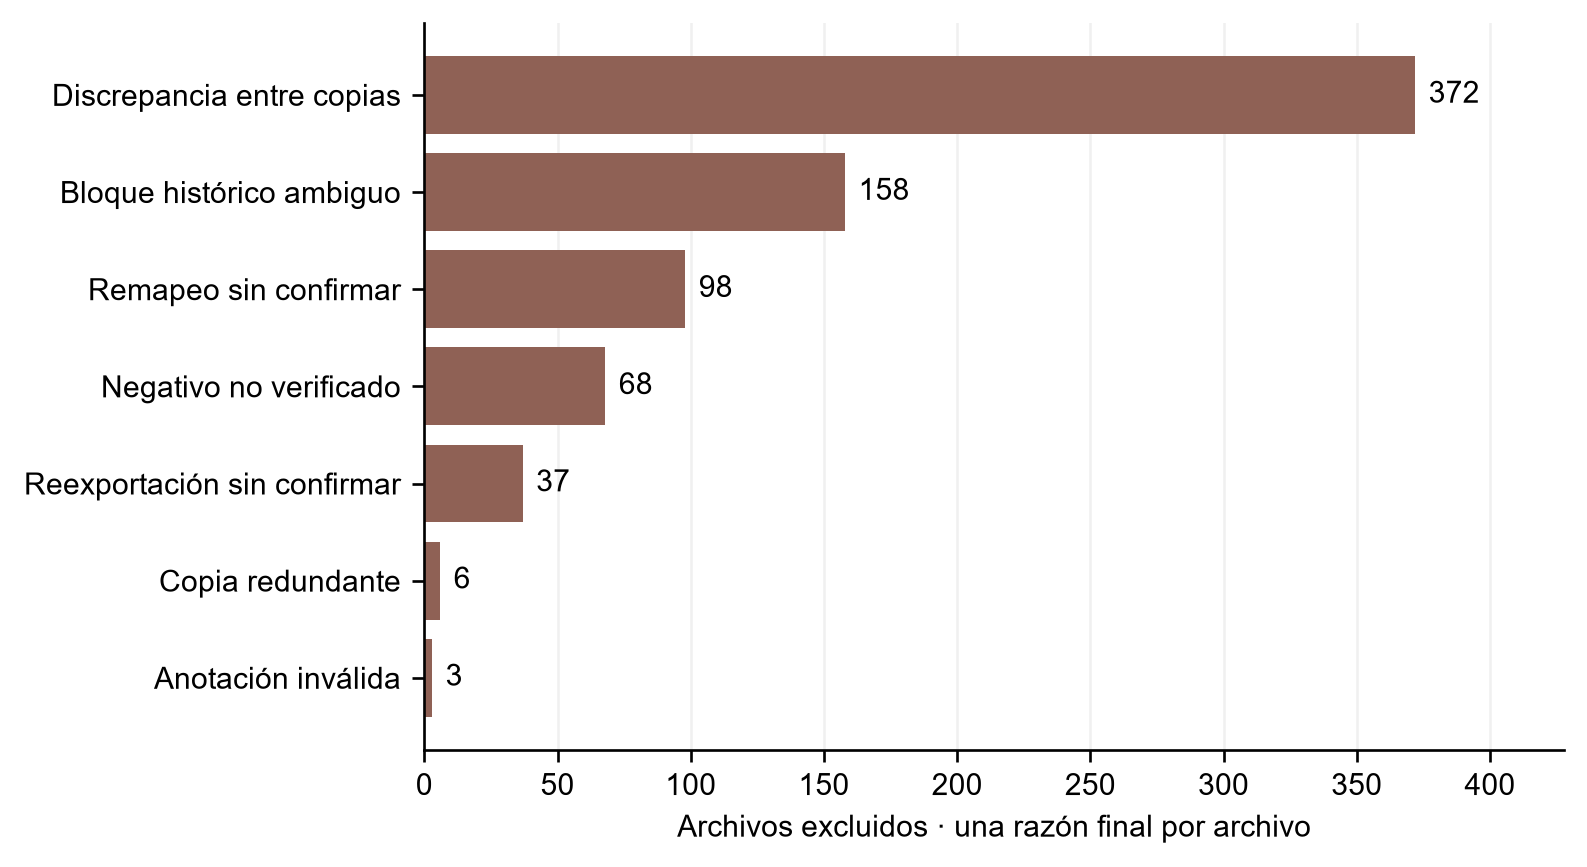

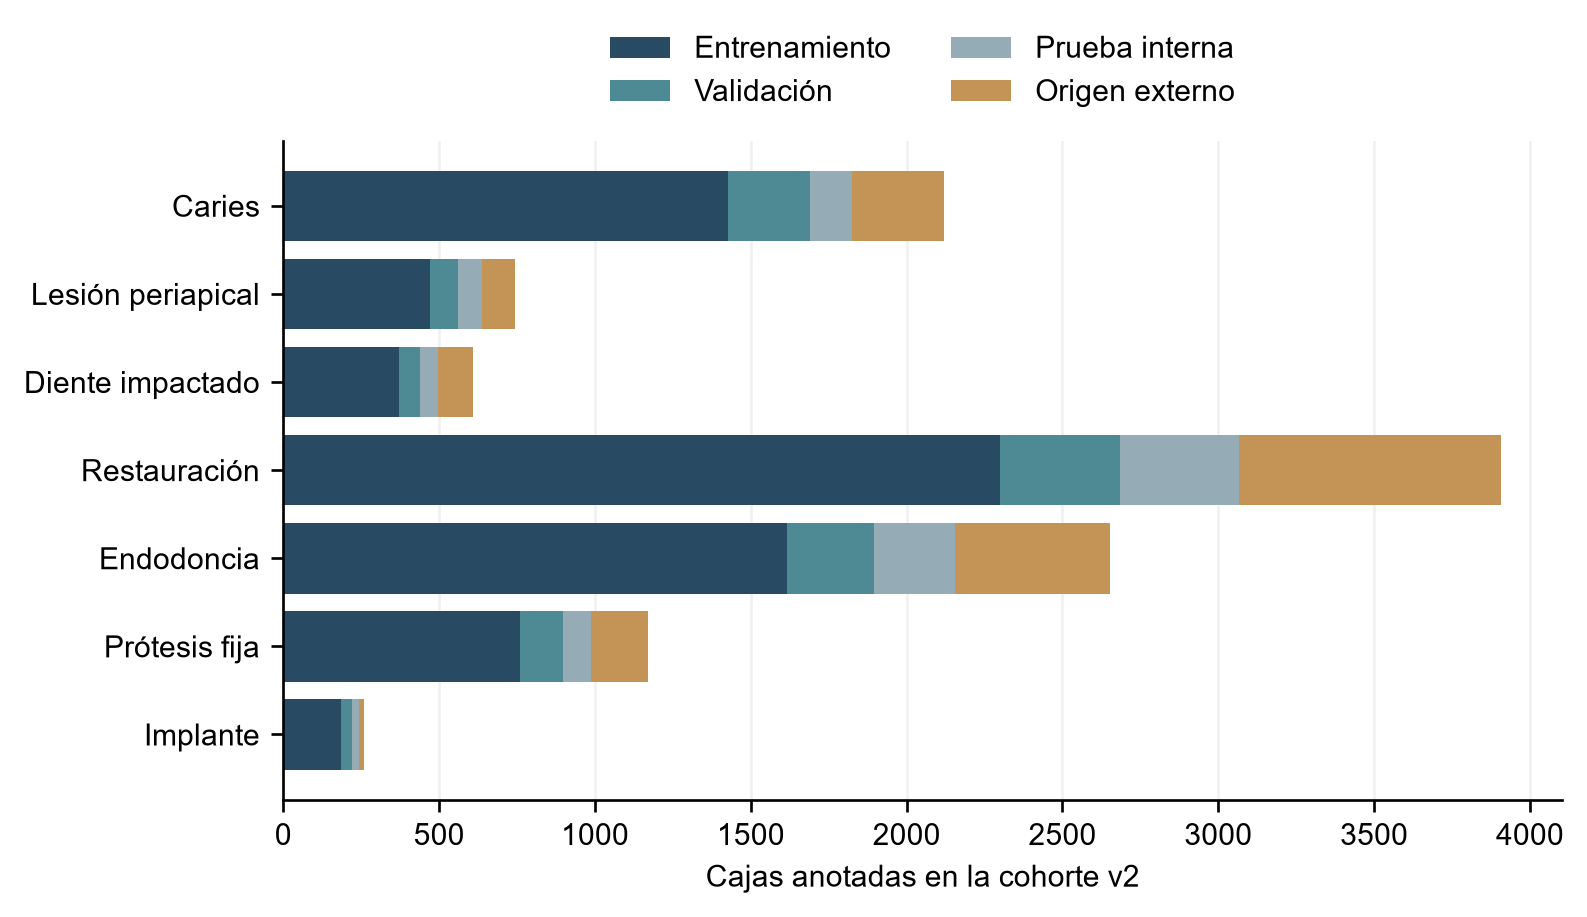

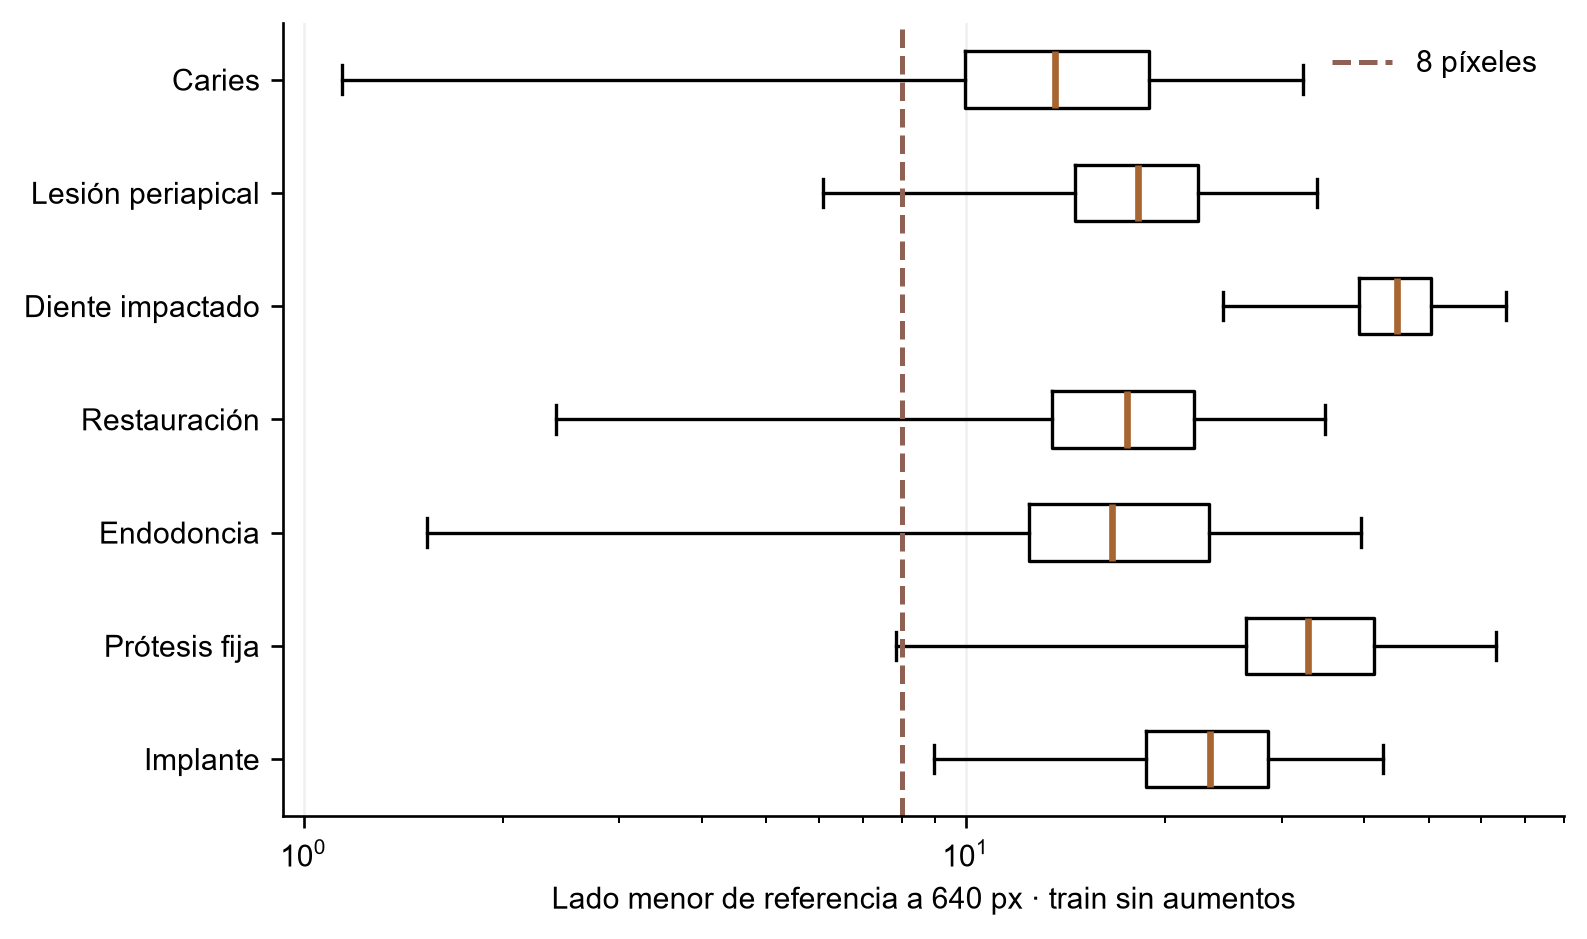

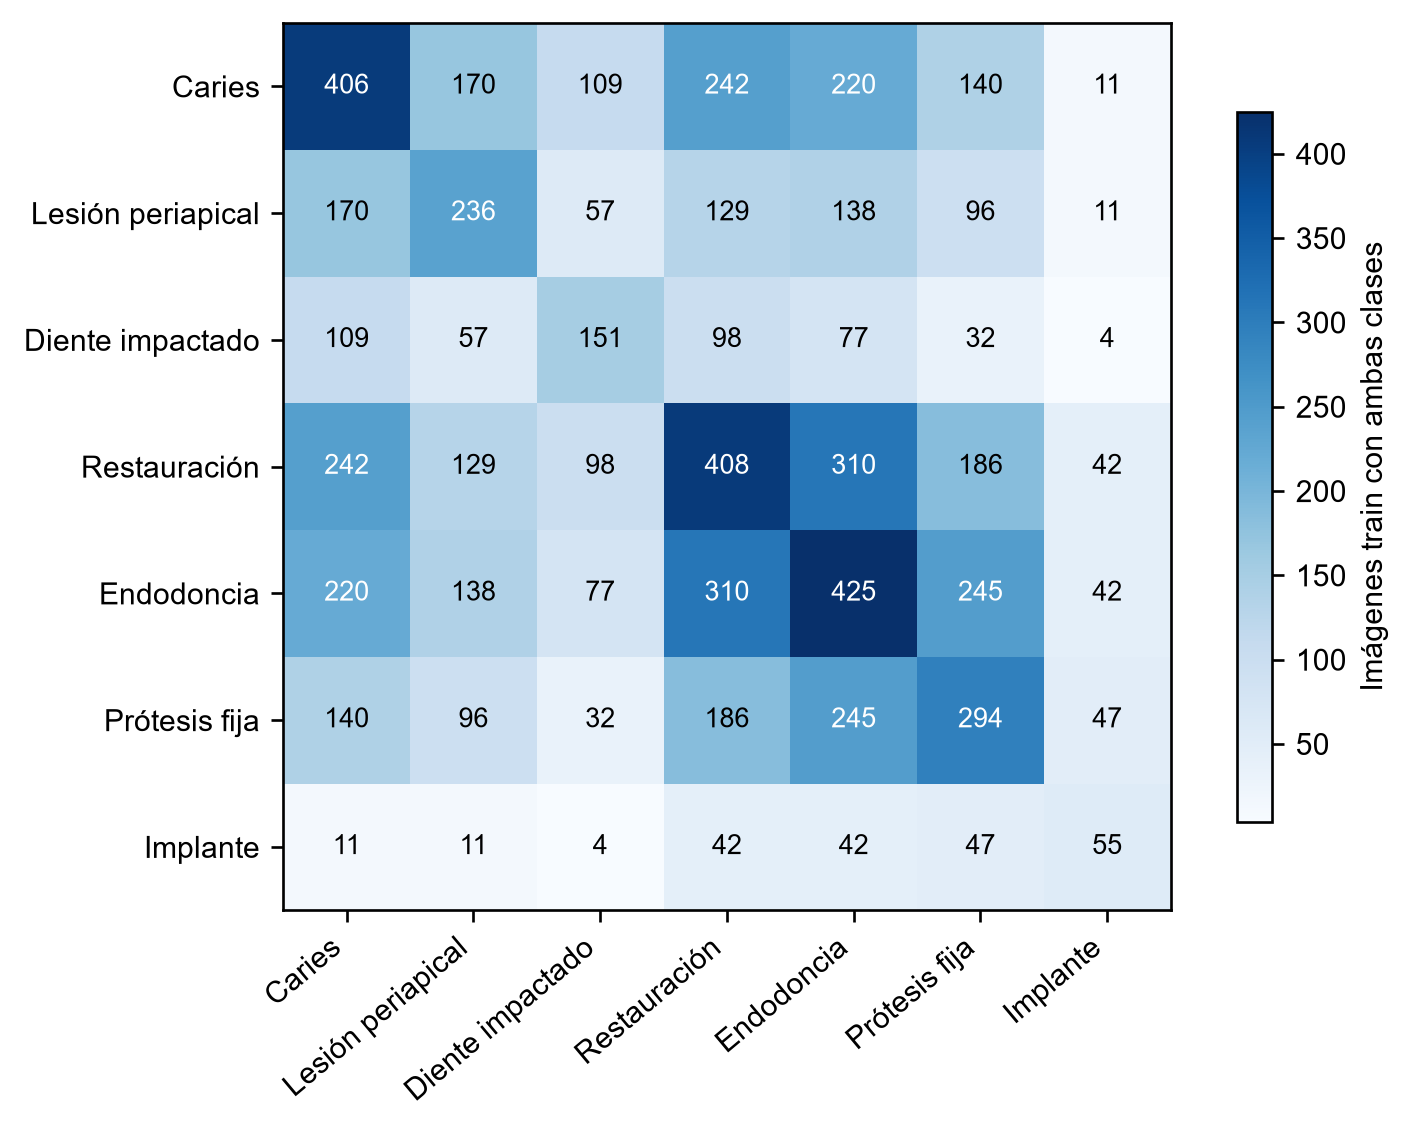

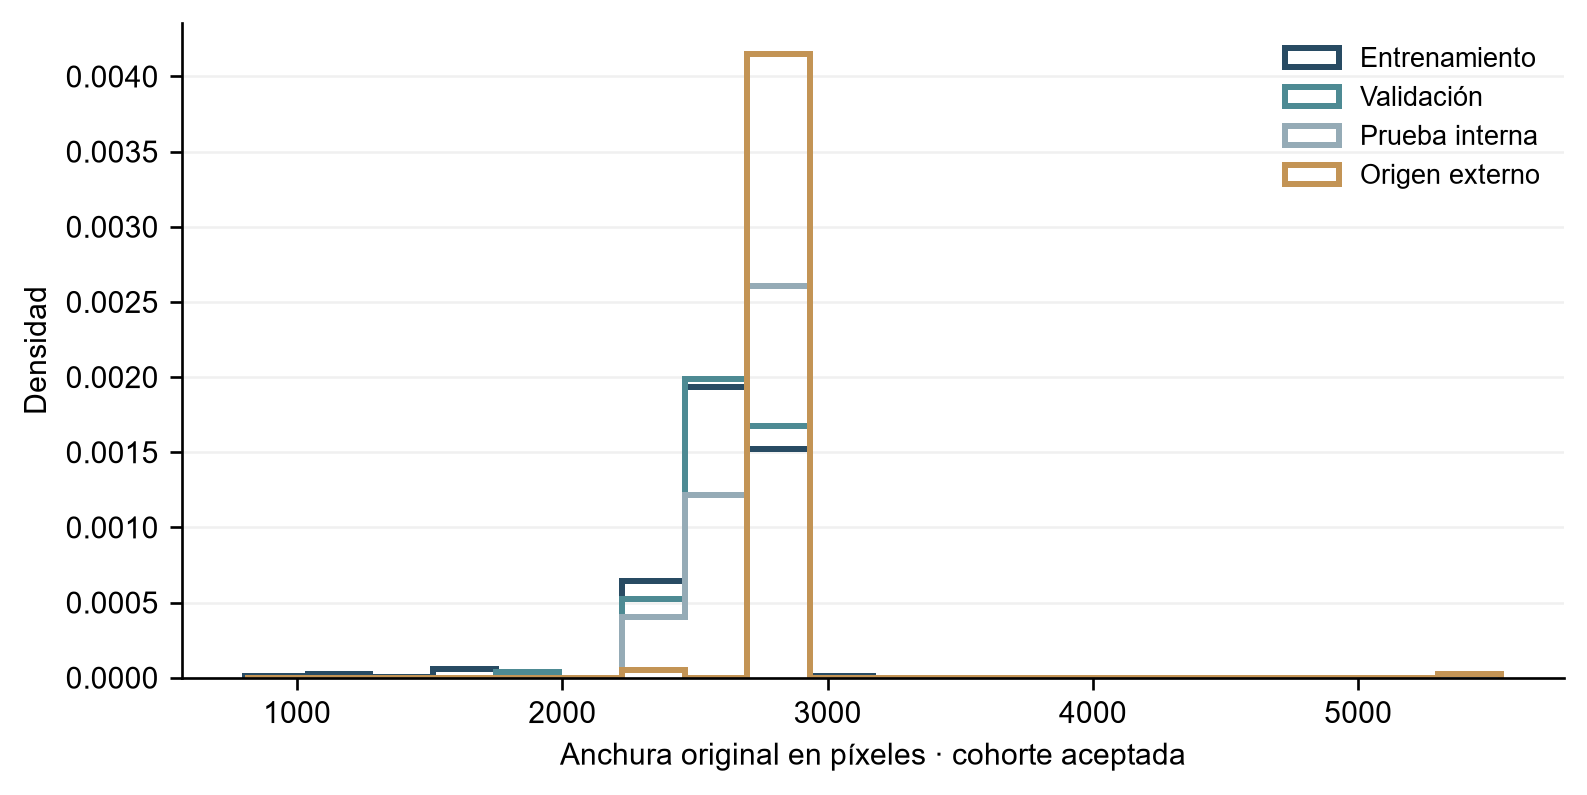

In [4]:
for name in ["v2_01_cohorte.png", "v2_02_exclusiones.png", "v2_03_clases.png", "v2_04_tamanos.png", "v2_05_coocurrencia.png", "v2_06_resoluciones.png"]:
    display(Image(filename=str(ROOT / "output/tesis/figures" / name)))

Las frecuencias son de archivos y cajas, no prevalencias por paciente. La política de exclusión restringe la población evaluada. Fuente: Mureșanu et al. (2025), https://doi.org/10.5281/zenodo.15487430 .